# 과제 ① 데이터 추출 및 분할


PDF 한 편을 **텍스트 / 표 / 이미지** 세 종류로 분리하는 코드를 **처음부터 직접 작성**합니다.

```
PDF 문서  ──▶  Unstructured Parser  ──▶  텍스트 / 표 / 이미지
```

# 0. 환경 검증

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치 — pip install {mod}")

Python: 3.12.3
가상환경 경로: /Users/huyn/Project/multimodal-rag/.venv
가상환경 안에서 실행 중? True

Poppler : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


# 1. 라이브러리 임포트

In [2]:
import os
import time
import pickle
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

print("임포트 완료")

임포트 완료


# 2. 경로 설정
- fname에 본인이 준비한 PDF 파일 이름을 적기

In [3]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in ("notebooks", "src") else Path.cwd()

# 실행할 pdf 파일 이름으로 저장
fname = "duolingo_q3_2025.pdf"

fpath = str(PROJECT_ROOT / "data") + os.sep
figures_fpath = str(PROJECT_ROOT / "data" / "figures_assignment") + os.sep

print("프로젝트 루트 :", PROJECT_ROOT)
print("PDF 폴더 :", fpath)
print("PDF 존재 여부 :", os.path.exists(fpath + fname))
print("figures 폴더 :", figures_fpath)

프로젝트 루트 : /Users/huyn/Project/multimodal-rag
PDF 폴더 : /Users/huyn/Project/multimodal-rag/data/
PDF 존재 여부 : True
figures 폴더 : /Users/huyn/Project/multimodal-rag/data/figures_assignment/


# 3. 추출 함수 만들기

In [4]:
def extract_pdf_elements(fpath, fname, figures_fpath):
    """
    PDF 파일에서 이미지, 테이플, 텍스트 블록을 추출.

    path: 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """

    return partition_pdf(
        filename=fpath + fname,
        strategy="hi_res",  # 정밀 추출 전략
        extract_images_in_pdf=True,     # 이미지 추출
        infer_table_structure=True,     # 표 구조 추론
        chunking_strategy="by_title",   # 타이틀 기준으로 텍스트 분할
        max_characters=4000,            # 최대 4000자로 블록 제한
        new_after_n_chars=3800,         # 3800자 이후 새 블록 생성
        combine_text_under_n_chars=2000,# 2000자 이하는 결합
        extract_image_block_output_dir=figures_fpath # 이미지 저장 경로
    )

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


# 4. 요소 분류 함수 만들기

In [5]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))     # tables 리스트에 표 저장 
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))      # texts 리스트에 텍스트 저장
    
    return texts, tables

print("categorize_elements 정의 완료")

categorize_elements 정의 완료


# 5. 추출 실행

In [6]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname, figures_fpath)

print(f"추출 완료 - {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1
No languages specified, defaulting to English.
W1110 12:23:45.496000 4320 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 367/367 [00:00<00:00, 9921.62it/s]


추출 완료 - 60.5초 소요
추출된 전체 요소 수: 32


In [7]:
texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수 :", len(tables))

텍스트 블록 수: 20
표 블록 수 : 12


# 6. 어떤 요소들이 나왔는지 집계

In [8]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 20개
Table                 : 12개


# 7. 추출된 이미지 확인

In [9]:
figures_dir = Path(figures_fpath)

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", "jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"    {f.name}    ({f.stat().st_size // 1024} KB)")
else:
    print("✗ figures_assignment 폴더가 없습니다.")

추출된 이미지: 7개

    figure-2-1.jpg    (34 KB)
    figure-23-7.jpg    (7 KB)
    figure-3-2.jpg    (147 KB)
    figure-3-3.jpg    (139 KB)
    figure-4-4.jpg    (235 KB)
    figure-5-5.jpg    (8 KB)
    figure-5-6.jpg    (7 KB)


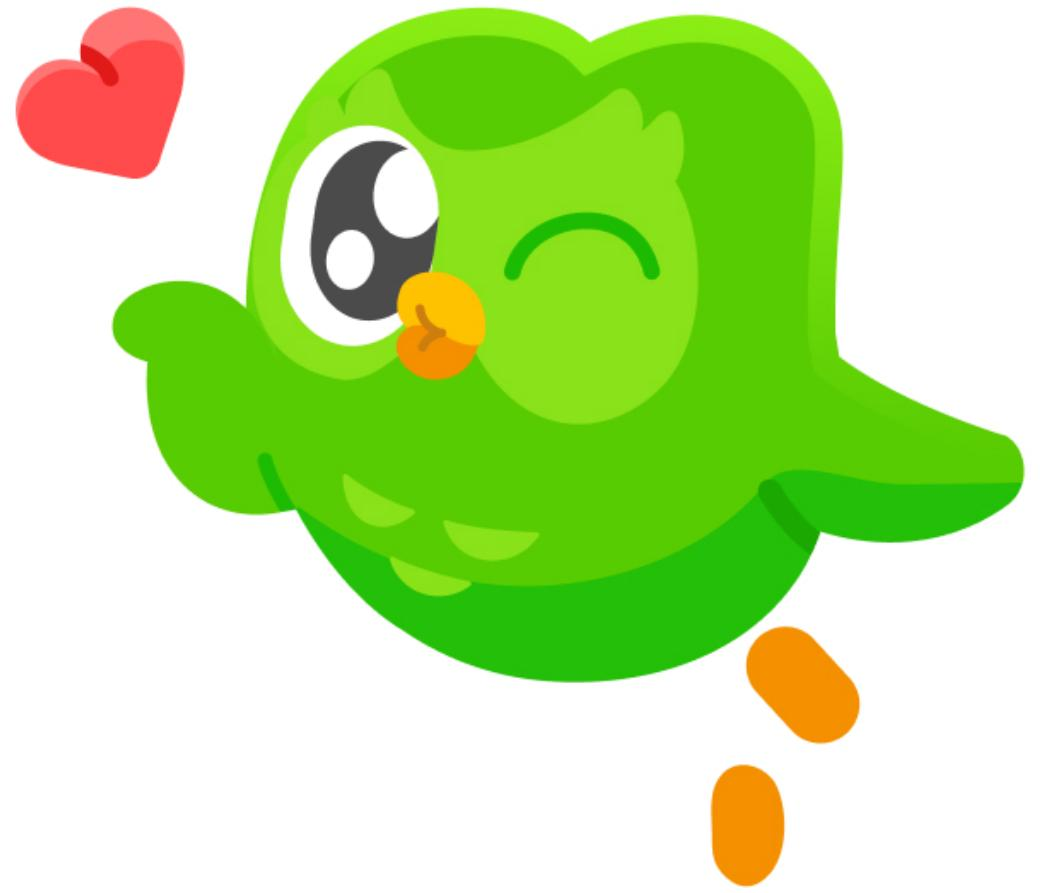

In [10]:
# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

# 8. 텍스트 분할
- 추출된 텍스트를 **2000자 단위로 다시 자릅니다.**

In [11]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,    # 각 테스트 블록의 최대 크기
    chunk_overlap=200,  # 청크 간 겹칠 글자수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수 : ", len(texts))
print("분할 후 블록 수 : ", len(texts_2k_token))
print("전체 글자 수 : ", len(joined_texts))

원본 블록 수 :  20
분할 후 블록 수 :  3
전체 글자 수 :  23924


# 9. 분할 결과 비교
원본과 분할된 텍스트의 첫 번째 요소를 비교합니다.

In [12]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
shareholder

letter Q3 2025

Wduolingo

our mission is to develop the best education in the world and make it universally available.

@ ZB

Q3 Highlights

User Metrics Daily Active Users Monthly Active Users Paid Subscribers at period end Paid Subscriber Penetration as % of LTM MAUs Q3 2024 37.2M 11

[분할 texts_2k_token[0]] 앞 300자
shareholder

letter Q3 2025

Wduolingo

our mission is to develop the best education in the world and make it universally available.

@ ZB

Q3 Highlights

User Metrics Daily Active Users Monthly Active Users Paid Subscribers at period end Paid Subscriber Penetration as % of LTM MAUs Q3 2024 37.2M 11


# 10. 저장

In [13]:
output_dir = PROJECT_ROOT / "data" / "processed_assignment"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

저장 완료: /Users/huyn/Project/multimodal-rag/data/processed_assignment/extracted.pkl
